## Is it a bird/forest/car?

In [1]:
# Run this notebook with the project .venv kernel (see ../../README.md next to this notebook).
# Live image search and the first download of pretrained weights need internet access.

In [2]:
# The project environment supplies the packages used throughout the lesson.
import sys
print(sys.executable)

c:\Users\Tarun\miniforge3\envs\scriptingsu\python.exe


## Step 1: Download images of birds and non-birds

In [3]:
# If search or image hosts are unavailable, follow "Use local photos" in ../../README.md
# and change this to True. The rest of the lesson can then run with your photos.
use_local_photos = False

In [4]:
from ddgs import DDGS
from fastcore.all import *

def search_images(keywords, max_images=200):
    return L(DDGS().images(keywords, max_results=max_images)).itemgot('image')

In [5]:
if not use_local_photos:
    urls = search_images('bird photos', max_images=1)
    display(urls[0])

'https://images.pexels.com/photos/326900/pexels-photo-326900.jpeg?cs=srgb&dl=wood-flight-bird-326900.jpg&fm=jpg'

c:\Users\Tarun\miniforge3\envs\scriptingsu\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


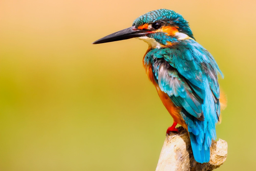

In [6]:
from fastdownload import download_url
dest = 'bird.jpg'
if not use_local_photos:
    download_url(urls[0], dest, show_progress=False, timeout=15)

from fastai.vision.all import *
im = Image.open(dest)
im.to_thumb(256,256)

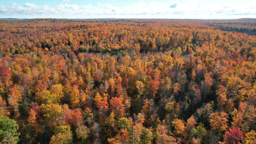

In [7]:
if not use_local_photos:
    download_url(search_images('forest photos', max_images=1)[0], 'forest.jpg', show_progress=False, timeout=15) 
Image.open('forest.jpg').to_thumb(256,256)

<div><progress max="2167909" value="2170880"></progress> 100.14% [2170880/2167909 00:00&lt;00:00]</div>

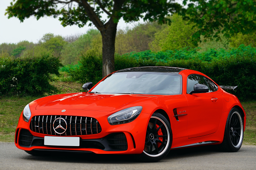

In [8]:
if not use_local_photos:
    download_url(search_images('car photos', max_images=1)[0], 'car.jpg', timeout=15)
Image.open('car.jpg').to_thumb(256,256)

In [9]:
searches = 'forest','bird','car'
path = Path('bird_or_not')
from time import sleep

for o in searches:
    dest = (path/o)
    if not use_local_photos:
        dest.mkdir(exist_ok=True, parents=True)
        download_images(dest, urls=search_images(f'{o} photo'))
        sleep(10)  # Pause between searches to avoid over-loading server
        download_images(dest, urls=search_images(f'{o} sun photo'))
        sleep(10)
        download_images(dest, urls=search_images(f'{o} shade photo'))
        sleep(10)
    resize_images(path/o, max_size=400, dest=path/o)

## Step 2: Train our model

In [10]:
failed = verify_images(get_image_files(path))
failed.map(Path.unlink)
len(failed)

93

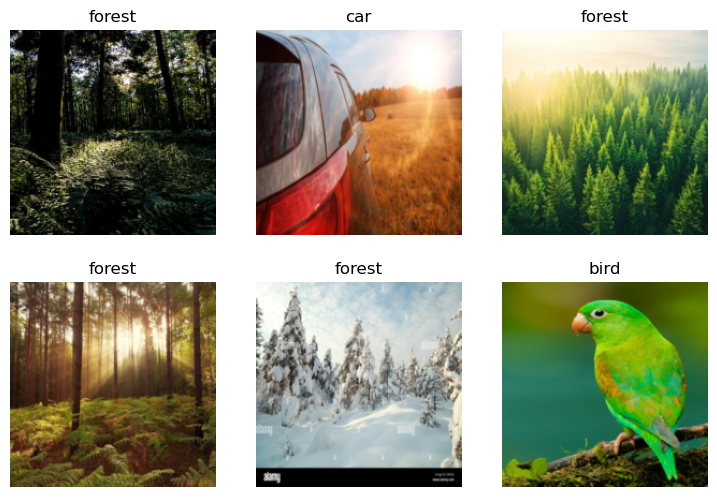

In [11]:
dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock), 
    get_items=get_image_files, 
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=[Resize(192, method='squish')]
).dataloaders(path)

dls.show_batch(max_n=6)

In [12]:
learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(3)

epoch,train_loss,valid_loss,error_rate,time
0,1.514632,0.696425,0.202899,00:10


epoch,train_loss,valid_loss,error_rate,time
0,0.279968,0.180748,0.086957,00:13
1,0.166077,0.044235,0.014493,00:13
2,0.115417,0.025499,0.014493,00:12


In [13]:
dls.vocab

['bird', 'car', 'forest']

## Step 3: Use our model (and build your own!)

In [17]:
is_bird,_,probs = learn.predict(PILImage.create('bird.jpg'))
print(f"This is a: {is_bird}.")
print(f"Probability it's a bird: {probs[0]:.4f} \nProbability it's a forest image: {probs[1]:.4f} \nProbability it's a car image: {probs[2]:.4f}")

<div><progress max="1" value="0"></progress> 0.00% [0/1 00:00&lt;?]</div>

This is a: bird.
Probability it's a bird: 0.9998 
Probability it's a forest image: 0.0001 
Probability it's a car image: 0.0000


In [19]:
is_car,_,probs = learn.predict(PILImage.create('car.jpg'))
print(f"This is a: {is_car}.")
print(f"Probability it's a bird image: {probs[0]:.4f} \nProbability it's a car image: {probs[1]:.4f} \nProbability it's a forest image: {probs[2]:.4f}")

This is a: car.
Probability it's a bird image: 0.0000 
Probability it's a car image: 1.0000 
Probability it's a forest image: 0.0000


# Challenge 2

In [20]:
learn_five = vision_learner(dls, resnet18, metrics=error_rate)
learn_five.fine_tune(5)

epoch,train_loss,valid_loss,error_rate,time
0,1.773283,0.416332,0.159420,00:11


epoch,train_loss,valid_loss,error_rate,time
0,0.255028,0.105909,0.057971,00:12
1,0.172141,0.016129,0.000000,00:12
2,0.115575,0.005109,0.000000,00:12
3,0.085290,0.002703,0.000000,00:12
4,0.066597,0.002174,0.000000,00:12


In [23]:
is_bird,_,probs = learn_five.predict(PILImage.create('bird.jpg'))
print(f"This is a: {is_bird}.")
print(f"Probability it's a bird: {probs[0]:.4f} \nProbability it's a forest image: {probs[1]:.4f} \nProbability it's a car image: {probs[2]:.4f}")

This is a: bird.
Probability it's a bird: 0.9999 
Probability it's a forest image: 0.0001 
Probability it's a car image: 0.0000


In [24]:
is_car,_,probs = learn_five.predict(PILImage.create('car.jpg'))
print(f"This is a: {is_car}.")
print(f"Probability it's a bird image: {probs[0]:.4f} \nProbability it's a car image: {probs[1]:.4f} \nProbability it's a forest image: {probs[2]:.4f}")

This is a: car.
Probability it's a bird image: 0.0000 
Probability it's a car image: 1.0000 
Probability it's a forest image: 0.0000
